# 01 · Исторические ARP: независимая сверка

**Исследовательский вопрос:** Совпадают ли восстановленные центры с опубликованными координатами выбранных исторических документов?

**Входные материалы:** реестры источников, локальные документы AIP и восстановленные центры из этапа 07 Европы

Расчеты ниже выполняются в ячейках. Все исходные строки сохраняются. Округление таблиц используется только для чтения результатов.

In [1]:
# Подключаем библиотеки и находим корень проекта
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display, Markdown
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'research/c40_geometry').is_dir())
study = root/'research/c40_geometry'
# Подключаем проверенные геодезические функции без запуска скриптов
sys.path.insert(0, str(root/'europe/scripts'))
from audit_c40_radial_cases import ellipsoid_distance, validate_distance
from investigate_c40_geometry import distance
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})
# Таблицы округляем только при отображении, расчетные значения сохраняем
pd.set_option('display.max_columns', 14)


## 1. Проверяем происхождение документов

Контрольная сумма подтверждает, что локальный документ совпадает с ранее сохраненным. Дата AIRAC, дата информации схемы и дата публикации не взаимозаменяемы.

In [2]:
# Проверяем целостность всех сохраненных источников
sources = json.loads((study/'literature/source_manifest.json').read_text(encoding='utf8'))
ad_sources = json.loads((study/'literature/historical_ad_manifest.json').read_text(encoding='utf8'))
checks = []
for item in sources + ad_sources:
    if item['status'] == 'saved':
        path = root/item['file']
        actual = hashlib.sha256(path.read_bytes()).hexdigest()
        assert actual == item['sha256'], str(path)
        checks.append({'Документ':path.name, 'SHA256 совпадает':True})
display(pd.DataFrame(checks))
# Показываем координаты вместе с датами и обозначением источника
pilot = pd.read_csv(study/'reports/historical_arp_sources.csv')
display(pilot[['airport','airac','designation','chart_information_date','publication_date',
               'published_lat','published_lon']])

,Документ,SHA256 совпадает
0,Figuet_et_al_2023_go_arounds.pdf,True
1,EUROCONTROL_OPADD_4_1_2021.pdf,True
2,Vincenty_1975_inverse.pdf,True
3,Karney_algorithms_geodesics_arxiv_1109_4448.pdf,True
4,NATS_EGLL_AIRAC_2019_12_05_chart.pdf,True
5,NATS_EGLL_AIRAC_2023_05_18_chart.pdf,True
6,NATS_EGCC_AIRAC_2019_11_07_chart.pdf,True
7,NATS_EGCC_AIRAC_2022_12_01_chart.pdf,True
8,NATS_EGCC_AIRAC_2019-11-07_AD2.html,True
9,NATS_EGCC_AIRAC_2020-01-30_AD2.html,True


,airport,airac,designation,chart_information_date,publication_date,published_lat,published_lon
0,EGLL,2019-12-05,explicit_ARP,2019-01-08,NaN,51.477500,-0.461389
1,EGLL,2023-05-18,explicit_ARP,2022-10-18,NaN,51.477500,-0.461389
2,EGCC,2019-11-07,chart_heading_AD2_2_supported,2019-06-20,NaN,53.353889,-2.275000
3,EGCC,2022-12-01,chart_heading_AD2_2_supported,2022-09-23,NaN,53.353889,-2.275000
4,EGCC,2019-11-07,explicit_ARP_AD2_2,NaN,2019-09-26,53.353889,-2.275000
5,EGCC,2020-01-30,explicit_ARP_AD2_2,NaN,2019-12-19,53.353889,-2.275000
6,EGCC,2020-02-27,explicit_ARP_AD2_2,NaN,2020-01-16,53.353889,-2.275000
7,EGCC,2021-02-25,explicit_ARP_AD2_2,NaN,2021-01-14,53.353889,-2.275000
8,EGLL,2019-12-05,explicit_ARP_AD2_2,NaN,2019-10-24,51.477500,-0.461389
9,EGLL,2023-05-18,explicit_ARP_AD2_2,NaN,2023-04-06,51.477500,-0.461389


## 2. Пересчитываем расхождение координат

Разности считаем в угловых секундах. Для практически совпадающих точек используем локальную линейную оценку расстояния; это не оценка точности слежения за самолетом.

In [3]:
# Присоединяем восстановленный центр по коду аэропорта
centers = pd.read_csv(root/'europe/reports/airports/c40_geometry/07_07_best_formula.csv')
comparison = pilot.merge(centers[['airport','fit_lat','fit_lon']], on='airport', validate='many_to_one')
# Переводим разности градусов в угловые секунды
comparison['delta_lat'] = (comparison.published_lat-comparison.fit_lat)*3600
comparison['delta_lon'] = (comparison.published_lon-comparison.fit_lon)*3600
# Оцениваем локальное расстояние с учетом широты
comparison['recomputed_m'] = 6371000*np.pi/(180*3600)*np.hypot(
    comparison.delta_lat, comparison.delta_lon*np.cos(np.radians(comparison.published_lat)))
assert np.allclose(comparison.recomputed_m, comparison.approximate_difference_m, atol=1e-7, rtol=0)
display(comparison[['airport','airac','source_id','delta_lat','delta_lon','recomputed_m']])

,airport,airac,source_id,delta_lat,delta_lon,recomputed_m
0,EGLL,2019-12-05,nats_egll_2019,-2.557954e-11,3.397282e-10,6.583072e-09
1,EGLL,2023-05-18,nats_egll_2023,-2.557954e-11,3.397282e-10,6.583072e-09
2,EGCC,2019-11-07,nats_egcc_2019,2.557954e-11,-1.598721e-12,7.906370e-10
3,EGCC,2022-12-01,nats_egcc_2022,2.557954e-11,-1.598721e-12,7.906370e-10
4,EGCC,2019-11-07,ad2_EGCC_2019-11-07,2.557954e-11,-1.598721e-12,7.906370e-10
5,EGCC,2020-01-30,ad2_EGCC_2020-01-30,2.557954e-11,-1.598721e-12,7.906370e-10
6,EGCC,2020-02-27,ad2_EGCC_2020-02-27,2.557954e-11,-1.598721e-12,7.906370e-10
7,EGCC,2021-02-25,ad2_EGCC_2021-02-25,2.557954e-11,-1.598721e-12,7.906370e-10
8,EGLL,2019-12-05,ad2_EGLL_2019-12-05,-2.557954e-11,3.397282e-10,6.583072e-09
9,EGLL,2023-05-18,ad2_EGLL_2023-05-18,-2.557954e-11,3.397282e-10,6.583072e-09


## 3. Показываем временное покрытие

Каждая отметка – отдельный проверенный срез. Линия времени не доказывает отсутствие изменений между документами.

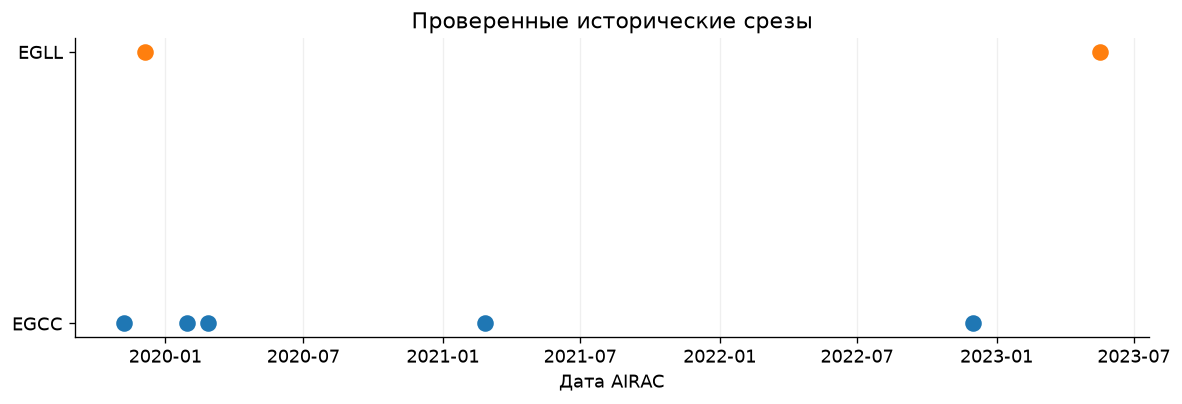

,airport,fit_lat,fit_lon,historical_status
0,EDDB,52.362222,13.500556,not_checked
1,EDDF,50.033333,8.570556,not_checked
2,EDDM,48.353889,11.786111,not_checked
3,EGCC,53.353889,-2.275000,ARP_matches_selected_AD2_2_2019_2021_snapshots
4,EGLL,51.477500,-0.461389,ARP_matches_selected_2019_2023_snapshots
5,EGSS,51.885000,0.235000,not_checked
6,EHAM,52.308056,4.764167,not_checked
7,EIDW,53.421389,-6.270000,not_checked
8,EKCH,55.618056,12.656111,not_checked
9,EPWA,52.165833,20.967222,not_checked


historical_status
not_checked                                       17
ARP_matches_selected_AD2_2_2019_2021_snapshots     1
ARP_matches_selected_2019_2023_snapshots           1
Name: Число аэропортов, dtype: int64

In [4]:
# Показываем доступные даты вступления в силу по каждому аэропорту
fig, ax = plt.subplots(figsize=(10,3.5))
for i, (airport, group) in enumerate(pilot.groupby('airport')):
    dates = pd.to_datetime(group.airac).drop_duplicates().sort_values()
    ax.scatter(dates, [i]*len(dates), s=80, label=airport)
ax.set(yticks=range(pilot.airport.nunique()), yticklabels=sorted(pilot.airport.unique()),
       xlabel='Дата AIRAC', title='Проверенные исторические срезы')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()
# Открытые аэропорты остаются явно отмеченными в общем реестре
registry = pd.read_csv(study/'reports/arp_reference_registry.csv')
display(registry)
display(registry.historical_status.value_counts().rename('Число аэропортов'))

## Что установлено и что остается открытым

Координаты выбранных документов сверены с центрами. Срезы не покрывают непрерывно весь период; ранняя часть 2019 года EGCC остается без этой независимой проверки. Совпадение ARP не объясняет механизм записи C40.

## Методические подробности и происхождение источников

# Исторические координаты: пилот EGLL и EGCC

Назначение ARP подтверждено по AD 2.2 обоих аэропортов. EGCC: середина ВПП 05L/23R; EGLL: середина ВПП 09L/27R. Шесть страниц HTML имеют внутреннюю дату вступления в силу, совпадающую с запрошенным AIRAC. Четыре PDF-схемы проверены отдельно; их даты информации перенесены в реестр. Печатные версии AD 2 по ссылкам из HTML вернули 404, HTML сохранены и проверены.

Срезы AIRAC не подтверждают непрерывную историю всего периода. Все записи сохраняются.

---

Разности координат приведены в угловых секундах. Почти нулевая разность подтверждает совпадение выбранных координат, но не подтверждает точность физического положения самолета или механизм записи C40. Первый проверенный документ EGCC имеет AIRAC 2019-11-07: ранняя часть 2019 года пока не покрыта этой независимой проверкой. Следующий шаг – остальные аэропорты и недостающие временные срезы.